# Image-processing options for the tumor contour

`skny.pp.calculate_distance` turns the tumor bins of a 10 µm grid into a binary image, smooths it, extracts the
contour and measures the distance of every bin from that contour. Since skny 0.3.4 the smoothing is configurable
through two arguments:

* `filters`: a list of image-processing steps applied in order to the binary tumor image
* `threshold`: the value (0–255) above which a filtered pixel counts as tumor

The default, `filters=[("median", 3), ("box", 3)]` with `threshold=90`, is the setting used in the paper
(Sakai *et al.*, *PLOS Comput Biol* 2025). This tutorial shows how to preview other settings with
`skny.pp.apply_filters` and how they change the contour, the distance bands and the tumor nests.

| step | meaning | typical use |
|---|---|---|
| `("median", k)` | median filter, `k` odd | remove isolated bins / salt-and-pepper noise |
| `("box", k)` | mean filter | soften the mask before thresholding |
| `("gaussian", k[, sigma])` | Gaussian filter | smoother contours than a box filter |
| `("open", k)` / `("close", k)` | morphological opening / closing (elliptical kernel) | remove thin protrusions / close small gaps |
| `("erode", k)` / `("dilate", k)` | shrink / grow the mask | |
| `"fill_holes"` | fill enclosed holes | treat stroma enclosed by tumor as tumor |
| `("min_area", n)` | drop connected components with fewer than `n` bins | ignore tiny nests |
| `"threshold"` | binarise at `threshold` at this point | mix linear and morphological steps |

The steps act on an 8-bit image (0 = background, 255 = tumor); linear filters blur it, morphological steps
reshape it and the final binarisation uses `threshold`. With the default 3 × 3 box filter, `threshold=90`
means "at least 4 of the 9 neighbouring bins are tumor".


## 1. Loading library

In [1]:
import skny as sk
import numpy as np
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")

## 2. Reading and gridding the Xenium data

The same public 10x Xenium breast cancer section as in the other tutorials
(`tutorial_data/xenium_data/`, see *Tumor contour with Xenium data* for the download commands).

In [2]:
adata = sk.pp.read_xenium(
    "tutorial_data/xenium_data/Xenium_FFPE_Human_Breast_Cancer_Rep1_cell_feature_matrix.h5",
    cells_file="tutorial_data/xenium_data/Xenium_FFPE_Human_Breast_Cancer_Rep1_cells.csv.gz",
)
grid = sk.pp.grid(adata, bin_um=10)

read_xenium: 167782 cells x 313 genes from Xenium_FFPE_Human_Breast_Cancer_Rep1_cell_feature_matrix.h5
Gridding 167782 cells into 547 rows x 752 cols ...


## 3. The default setting

`calculate_distance` stores the raw tumor image in `grid.uns["marker"]`, the smoothed image in
`grid.uns["marker_median"]` and the settings in `grid.uns["image_processing"]`.

In [3]:
grid = sk.pp.calculate_distance(grid, pos_marker_ls=["CDH1"])
grid.uns["image_processing"]

{'filters': ['median 3', 'box 3'], 'threshold': 90}

In [4]:
sk.pl.preprocessed_images(grid, figsize=(800, None))

## 4. Previewing other settings with `apply_filters`

`sk.pp.apply_filters(mask, filters, threshold)` returns the smoothed boolean mask without running the (slow)
distance calculation, so different settings can be compared in seconds. Here we look at a region of interest
with ductal carcinoma in situ (DCIS) and invasive nests.

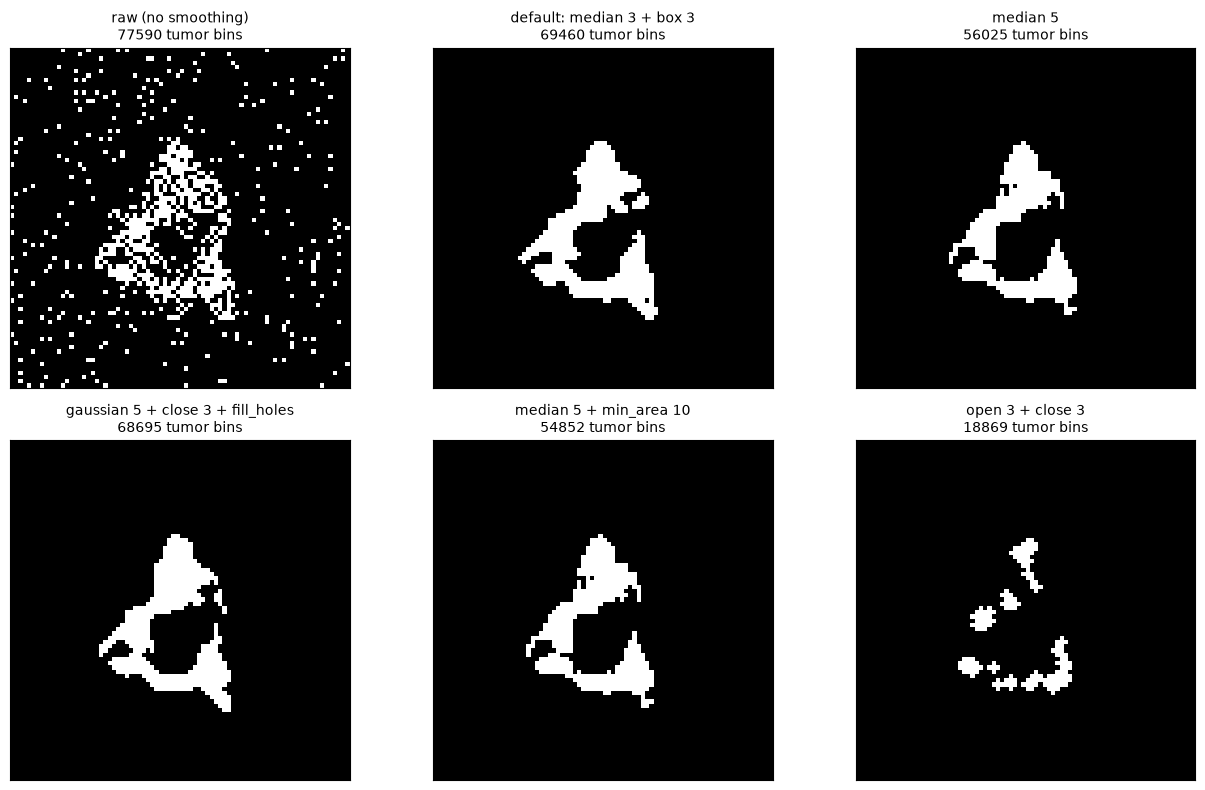

In [5]:
settings = {
    "raw (no smoothing)": None,
    "default: median 3 + box 3": [("median", 3), ("box", 3)],
    "median 5": [("median", 5)],
    "gaussian 5 + close 3 + fill_holes": [("gaussian", 5), ("close", 3), "fill_holes"],
    "median 5 + min_area 10": [("median", 5), ("min_area", 10)],
    "open 3 + close 3": [("open", 3), ("close", 3)],
}
raw = grid.uns["marker"]
roi = (slice(250, 330), slice(240, 320))   # rows, cols in grid units (10 um) = ROI #1 of the Xenium tutorial

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (name, filters) in zip(axes.ravel(), settings.items()):
    mask = sk.pp.apply_filters(raw, filters=filters, threshold=128 if name.startswith("gaussian") else 90)
    ax.imshow(mask[roi], cmap="gray", interpolation="nearest")
    ax.set_title(f"{name}\n{int(mask.sum())} tumor bins", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

The raw mask is fragmented (single bins with a few *CDH1* transcripts scattered over the stroma); the default
smoothing removes them and fills the duct wall while keeping the lumen, which is open to the stroma at the lower
left. `median 5` and `median 5 + min_area 10` are more conservative, `gaussian 5 + close 3 + fill_holes` gives
the smoothest contour (the lumen is not filled here because it is not enclosed). `open 3 + close 3` removes most
of the duct: on a 10 µm grid a 3-bin opening erodes every structure thinner than about 30 µm, so use opening
only with structures clearly larger than the kernel. The raw mask is shown for comparison only:
`calculate_distance` requires at least one smoothing step, because without it the contour fragments into
thousands of pieces and the distance calculation takes very long.

## 5. Running the distance calculation with another setting

Pass the chosen steps to `calculate_distance`. Everything downstream (equidistant curves, expression along the
distance, per-nest objects) works unchanged.

In [6]:
grid_smooth = sk.pp.grid(adata, bin_um=10)
grid_smooth = sk.pp.calculate_distance(
    grid_smooth, pos_marker_ls=["CDH1"],
    filters=[("gaussian", 5), ("close", 3), "fill_holes"], threshold=128,
)
grid_smooth.uns["image_processing"]

Gridding 167782 cells into 547 rows x 752 cols ...


{'filters': ['gaussian 5', 'close 3', 'fill_holes'], 'threshold': 128}

In [7]:
sk.pl.equidistant_curves(grid_smooth, figsize=(500, None))

### Effect on the distance bands and the tumor nests

In [8]:
def summary(g, name):
    bands = g.shortest.dropna()["region"].apply(lambda i: i.right)
    n_nests = sk.pp.convert_indivisual_solid(g).n_obs
    print(f"{name:38s} intra-tumoral bins: {int((bands <= 0).sum()):6d}   "
          f"peri-tumoral bins (0, 30] um: {int((bands == 3).sum()):6d}   tumor nests: {n_nests}")

summary(grid, "default (median 3 + box 3, thr 90)")
summary(grid_smooth, "gaussian 5 + close 3 + fill_holes, thr 128")

Calculatting gene expression of (-∞, 0]


default (median 3 + box 3, thr 90)     intra-tumoral bins:  69460   peri-tumoral bins (0, 30] um:  66841   tumor nests: 535
Calculatting gene expression of (-∞, 0]


gaussian 5 + close 3 + fill_holes, thr 128 intra-tumoral bins:  66889   peri-tumoral bins (0, 30] um:  64656   tumor nests: 564


### Effect on the expression profile along the distance

The myoepithelial marker *KRT15* peaks in the (-30, 0] and (0, 30] bands, i.e. at the contour, with both
settings; compare the two profiles to see how much a smoother domain shifts the signal between the two bands.

In [9]:
sk.pl.distance_gene_plot(grid, "KRT15")

In [10]:
sk.pl.distance_gene_plot(grid_smooth, "KRT15")

## 6. Which setting should I use?

* Keep the **default** to reproduce the paper and for most Xenium / CosMx panels.
* Use a **larger median** or **`min_area`** when the marker is noisy (ambient transcripts, sparse panels) and
  small spurious nests appear.
* Use **`close` / `fill_holes`** when the tumor contains stroma or lumina that should count as intra-tumoral.
* Use **`open`** to cut thin bridges between nests that should be analysed separately (single-TME analysis).
* Raise **`threshold`** (e.g. 128 = more than half of the neighbourhood) for a stricter domain, lower it for a
  more inclusive one.

The settings are stored in `grid.uns["image_processing"]` and saved with the object (`grid.write_h5ad`), so an
analysis can always be traced back to the filters that produced it. The same arguments apply to label-defined
domains (`use_label` / `pos_label_ls`, see *Tumor core / margin / dist analysis with cell-type labels*).